# Clase 5 — Despliegue de modelos y predicción por lotes

**Objetivo:** distinguir predicción **por lotes** (*batch*) y **en línea** (*online*), medir por qué
el batch es tan eficiente y armar el patrón de la clase 5 de la materia: precalcular predicciones,
guardarlas en un almacén clave-valor y servirlas con una simple búsqueda.

Es lo que hace el DAG `batch_predict_burnout` del TP.

In [1]:
from helpers import OUT, check, cuestionario, quiz, safe_check, tarjetas

import hashlib
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ipywidgets import interact, widgets

from burnout.batch import predict_batch
from burnout.config import BEST_PARAMS_AMQ1, DATA_RAW, OUTCOMES
from burnout.data import load_raw, make_split
from burnout.model import make_pipeline

X_train, X_test, y_train, y_test = make_split(load_raw())
modelo = make_pipeline(**BEST_PARAMS_AMQ1).fit(X_train, y_train)  # en el TP: el champion de MLflow
print("Modelo listo")

Modelo listo


## 📖 Teoría: cómo llega una predicción al usuario

Entrenar un modelo no le sirve a nadie hasta que sus predicciones **llegan a quien decide**. Hay dos
grandes patrones, y la elección depende de **cuándo se necesita la predicción** y **qué datos hay en
ese momento**.

```mermaid
flowchart LR
    subgraph Batch["Batch (por lotes)"]
        direction LR
        D1[("datos de<br>muchos registros")] --> J["job programado<br>(Airflow)"]
        J --> P1[("predicciones<br>guardadas")]
        P1 --> U1["usuario consulta<br>(búsqueda O(1))"]
    end
    subgraph Online["Online (en línea)"]
        direction LR
        U2["usuario envía<br>un pedido"] --> API["API<br>(FastAPI)"]
        API --> M["modelo<br>en memoria"]
        M --> API
        API --> U2
    end
```

| | Batch | Online |
|---|---|---|
| Cuándo se predice | en horario programado, para todos | en el momento del pedido, para uno |
| Latencia para el usuario | mínima (ya está calculado) | la del modelo + la red (ms) |
| Frescura | puede estar desactualizada | siempre al día |
| Registros nuevos | sin predicción hasta la próxima corrida | se predicen al instante |
| Infraestructura | un job y un almacén | servicio siempre arriba, escalable, monitoreado |
| Costo | bajo | más alto |
| En el TP | DAG `batch_predict_burnout` (1ª entrega) | API FastAPI (2ª entrega) |

**El patrón de la clase 5: precalcular y servir.** Se predice en lote, se guarda cada resultado en un
**almacén clave-valor** (Redis/Valkey, DynamoDB) con una clave (el ID, o un hash de las features), y el
servicio solo **busca**. Combina la baja latencia del online con el bajo costo del batch, siempre que
las entradas se conozcan de antemano.

**Despliegue de una versión nueva del modelo.** Cambiar el modelo en producción es un riesgo. Las
estrategias reparten ese riesgo:

```mermaid
flowchart TB
    subgraph BG["Blue/green"]
        LB1["tráfico"] -- "100 %" --> G["green (nuevo)"]
        LB1 -. "0 %, listo para volver" .-> B["blue (viejo)"]
    end
    subgraph CN["Canary"]
        LB2["tráfico"] -- "95 %" --> V2["viejo"]
        LB2 -- "5 % → 25 % → 100 %" --> N2["nuevo"]
    end
    subgraph SH["Shadow"]
        LB3["tráfico"] -- "100 %, responde" --> V3["viejo"]
        LB3 -. "copia, no responde" .-> N3["nuevo"]
    end
```

- **Blue/green:** dos entornos completos; se cambia todo el tráfico de golpe y el viejo queda para un
  rollback instantáneo.
- **Canary:** el nuevo recibe un porcentaje chico que se aumenta si las métricas acompañan.
- **Shadow:** el nuevo recibe una copia del tráfico, predice y se compara, pero no responde a nadie.
- **A/B:** dos modelos sirven a grupos distintos de usuarios y se decide con una prueba estadística
  sobre un resultado de negocio.

En el TP, el **alias `champion` de MLflow** hace de "interruptor": mover el alias es el blue/green del
batch.

## 1. Batch vs online

| | **Por lotes** | **En línea** |
|---|---|---|
| Cuándo se predice | periódicamente (p. ej. cada noche), para muchos casos | en el momento, cuando llega un pedido |
| Latencia para quien consulta | mínima (ya está calculado) | la del modelo |
| Frescura | puede estar desactualizada | siempre al día |
| Casos nuevos | sin predicción hasta el próximo lote | sin problema |
| En el TP | DAG `batch_predict_burnout` (1ª entrega) | API con FastAPI (2ª entrega) |

In [2]:
quiz(
    "La universidad quiere un reporte semanal con el riesgo de burnout de todos sus estudiantes "
    "para planificar tutorías. ¿Qué conviene?",
    ["Predicción por lotes", "Predicción en línea", "Reentrenar el modelo cada semana"],
    answer=0,
    explanation="No hace falta respuesta inmediata y son muchos estudiantes a la vez: es el caso típico de batch.",
)

**La universidad quiere un reporte semanal con el riesgo de burnout de todos sus estudiantes para planificar tutorías. ¿Qué conviene?**

ToggleButtons(options=('Predicción por lotes', 'Predicción en línea', 'Reentrenar el modelo cada semana'), sty…

Output()

In [3]:
quiz(
    "Un estudiante completa un formulario en la web y quiere ver su riesgo al instante. ¿Qué conviene?",
    ["Predicción por lotes", "Predicción en línea"],
    answer=1,
    explanation="El caso es nuevo y la respuesta tiene que ser inmediata: online (la API de la 2ª entrega).",
)

**Un estudiante completa un formulario en la web y quiere ver su riesgo al instante. ¿Qué conviene?**

ToggleButtons(options=('Predicción por lotes', 'Predicción en línea'), style=ToggleButtonsStyle(button_width='…

Output()

## 2. 🎛️ ¿Por qué el batch es tan eficiente?
Predecir de a una fila paga el costo fijo (validar, preprocesar, llamar a XGBoost) en **cada**
llamada. En lote, ese costo se reparte. Mové el tamaño del lote:

In [4]:
@interact(tamano=widgets.SelectionSlider(options=[1, 10, 100, 1_000, 10_000], value=100))
def medir(tamano):
    lote = X_test.head(tamano)
    t0 = time.perf_counter()
    modelo.predict(lote)
    t_lote = time.perf_counter() - t0

    n_uno = min(tamano, 200)  # de a una (medimos hasta 200 y extrapolamos)
    t0 = time.perf_counter()
    for i in range(n_uno):
        modelo.predict(lote.iloc[[i]])
    t_uno = (time.perf_counter() - t0) / n_uno * tamano

    print(f"Lote de {tamano:>6}: {t_lote * 1000:8.1f} ms en total → {t_lote / tamano * 1e6:9.1f} µs por estudiante")
    print(f"De a uno       : {t_uno * 1000:8.1f} ms en total → {t_uno / tamano * 1e6:9.1f} µs por estudiante")
    print(f"El lote es ≈ {t_uno / t_lote:,.0f} veces más rápido")

interactive(children=(SelectionSlider(description='tamano', index=2, options=(1, 10, 100, 1000, 10000), value=…

## 3. Predecir un lote con el código del TP
Simulamos estudiantes "nuevos": filas del dataset **sin** las variables que se miden a fin de
semestre (igual que el DAG). `predict_batch` es la misma función que usa la tarea `predict`.

In [5]:
lote = pd.read_csv(DATA_RAW).sample(2_000, random_state=1).drop(columns=OUTCOMES)
predicciones = predict_batch(modelo, lote)
predicciones.head()

,Student_ID,proba_Low,proba_Medium,proba_High,Burnout_Risk_Pred
0,126248,0.4685,0.4407,0.0907,Low
1,135068,0.3197,0.4852,0.1951,Medium
2,134591,0.3536,0.4967,0.1497,Medium
3,116669,0.1451,0.4340,0.4209,Medium
4,112197,0.6016,0.3505,0.0479,Low


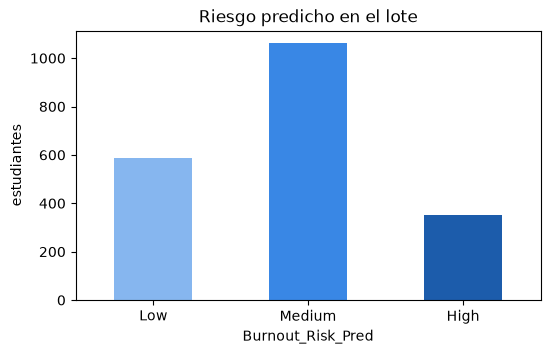

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
predicciones["Burnout_Risk_Pred"].value_counts().reindex(["Low", "Medium", "High"]).plot.bar(
    ax=ax, color=["#86b6ef", "#3987e5", "#1c5cab"], rot=0)
ax.set(title="Riesgo predicho en el lote", ylabel="estudiantes")
plt.show()

## 4. Servir predicciones precalculadas: almacén clave-valor
En la clase 5 de la materia las predicciones se guardan en **Redis/Valkey** con una clave por
caso. Acá usamos **SQLite** como clave-valor (viene con Python), pero la idea es la misma:
el servicio que consulta **no necesita el modelo**, solo hace un `GET` por clave.

¿Qué clave usamos?

- Si el caso tiene identificador (nuestro `Student_ID`), esa es la clave.
- Si no, se usa un **hash de las features** (como en la clase 5): mismas features → misma clave.

### ✏️ Ejercicio 1 — clave por hash
Completá `clave(fila)` para que devuelva el SHA-256 (en hexadecimal) del texto que se arma uniendo
con espacios los valores de las features **redondeando los números a 2 decimales**.

In [7]:
from burnout.config import FEATURE_COLUMNS


def clave(fila: pd.Series) -> str:
    valores = [str(round(v, 2)) if isinstance(v, (int, float, np.number)) else str(v) for v in fila[FEATURE_COLUMNS]]
    texto = " ".join(valores)
    ...  # ← tu código acá: devolvé hashlib.sha256(...).hexdigest()

In [8]:
fila = lote.iloc[0]
esperado = hashlib.sha256(" ".join(
    str(round(v, 2)) if isinstance(v, (int, float, np.number)) else str(v) for v in fila[FEATURE_COLUMNS]
).encode()).hexdigest()
safe_check("Ejercicio 1", lambda: clave(fila) == esperado,
           "`return hashlib.sha256(texto.encode()).hexdigest()` (hay que pasar el texto a bytes con `.encode()`).")

⏳ **Ejercicio 1**: todavía no. *Pista:* `return hashlib.sha256(texto.encode()).hexdigest()` (hay que pasar el texto a bytes con `.encode()`).

False

<details><summary>Ver solución</summary>

```python
    return hashlib.sha256(texto.encode()).hexdigest()
```
</details>

Guardamos el lote en el almacén. Si el ejercicio no está resuelto, usamos el `Student_ID` como clave.

In [9]:
usa_hash = clave(fila) == esperado if callable(clave) else False
db = sqlite3.connect(OUT / "predicciones.db")
db.execute("DROP TABLE IF EXISTS kv")
db.execute("CREATE TABLE kv (clave TEXT PRIMARY KEY, valor TEXT)")

claves = [clave(r) for _, r in lote.iterrows()] if usa_hash else lote["Student_ID"].astype(str).tolist()
db.executemany("INSERT OR REPLACE INTO kv VALUES (?, ?)", zip(claves, predicciones["Burnout_Risk_Pred"], strict=True))
db.commit()
print(f"{db.execute('SELECT COUNT(*) FROM kv').fetchone()[0]} predicciones guardadas (clave: {'hash' if usa_hash else 'Student_ID'})")

2000 predicciones guardadas (clave: Student_ID)


### 🎛️ El "servicio" de consulta
Elegí un estudiante del lote, o uno que **no** está en el lote: ahí aparece la principal debilidad
del batch, y hace falta un valor por defecto (en la clase 5 se devolvía la clase más frecuente).

In [10]:
POR_DEFECTO = "Medium"  # la clase más frecuente
fuera_del_lote = pd.read_csv(DATA_RAW).drop(columns=OUTCOMES).loc[lambda d: ~d["Student_ID"].isin(lote["Student_ID"])].head(3)
opciones = {f"{r['Student_ID']} (en el lote)": r for _, r in lote.head(5).iterrows()}
opciones |= {f"{r['Student_ID']} (NUEVO)": r for _, r in fuera_del_lote.iterrows()}


def consultar(fila: pd.Series) -> tuple[str, float]:
    k = clave(fila) if usa_hash else str(fila["Student_ID"])
    t0 = time.perf_counter()
    res = db.execute("SELECT valor FROM kv WHERE clave = ?", (k,)).fetchone()
    return (res[0] if res else None), (time.perf_counter() - t0) * 1e6


@interact(estudiante=widgets.Dropdown(options=list(opciones)))
def servicio(estudiante):
    valor, us = consultar(opciones[estudiante])
    if valor is None:
        print(f"⚠️ Sin predicción precalculada ({us:.0f} µs) → devolvemos el valor por defecto: {POR_DEFECTO}")
    else:
        print(f"Riesgo de burnout: {valor}   (búsqueda en {us:.0f} µs, sin cargar el modelo)")

interactive(children=(Dropdown(description='estudiante', options=('126248 (en el lote)', '135068 (en el lote)'…

## 5. Estrategias de despliegue (para la 2ª entrega)
Cuando el DAG de reentrenamiento promueva un modelo nuevo, ¿cómo lo ponemos en producción sin riesgo?

| Estrategia | Idea |
|---|---|
| **Shadow** | el modelo nuevo predice en paralelo, pero sus respuestas no se usan: solo se comparan |
| **Canary** | una fracción chica del tráfico va al modelo nuevo; si va bien, se amplía |
| **A/B testing** | se reparte el tráfico para medir cuál funciona mejor según una métrica de negocio |
| **Blue/green** | dos entornos completos; se cambia todo el tráfico de uno a otro de golpe (y se puede volver) |

In [11]:
quiz(
    "Queremos probar el challenger con datos reales sin que ningún usuario reciba sus predicciones. ¿Qué estrategia es?",
    ["Canary", "Shadow", "Blue/green"],
    answer=1,
    explanation="En shadow el modelo nuevo corre 'a la sombra': se registran sus predicciones para compararlas.",
)

**Queremos probar el challenger con datos reales sin que ningún usuario reciba sus predicciones. ¿Qué estrategia es?**

ToggleButtons(options=('Canary', 'Shadow', 'Blue/green'), style=ToggleButtonsStyle(button_width='auto'), value…

Output()

## 6. En el TP (con Docker)
El DAG `batch_predict_burnout` (`@daily`):

1. arma el lote en `s3://data/burnout/batch/input.csv` (si no existe, toma una muestra del crudo; el
   tamaño sale de la variable de Airflow `burnout_batch_size`);
2. carga `models:/burnout_model_prod@champion`;
3. guarda las predicciones en `s3://data/burnout/batch/predictions.csv`.

Para leerlas desde tu máquina con el entorno levantado:

```python
import os
os.environ |= {"AWS_ACCESS_KEY_ID": "minio", "AWS_SECRET_ACCESS_KEY": "minio123",
               "AWS_ENDPOINT_URL_S3": "http://localhost:9000"}
from burnout import storage
storage.read_csv("burnout/batch/predictions.csv").head()
```

In [12]:
db.close()

## 🏭 Casos de uso y ejemplos

### En la industria

- **Netflix** describió en 2013 su arquitectura de recomendaciones en tres capas: **offline** (batch
  pesado sobre todos los usuarios), **nearline** (reacciona a eventos en minutos) y **online**
  (responde al instante). La mayoría de los sistemas reales combinan batch y online.
- **Fraude con tarjeta:** online sí o sí. La compra se aprueba o se rechaza en milisegundos, con datos
  de esa transacción.
- **Riesgo crediticio y churn:** típicamente batch. Cada noche o cada semana se puntúan todos los
  clientes y las áreas comerciales trabajan con esa lista.
- **Knight Capital (2012).** Un despliegue manual dejó a uno de sus 8 servidores con código viejo, que
  se activó por error y en 45 minutos generó pérdidas por unos 440 millones de dólares. No era un
  modelo de ML, pero es la lección clásica de por qué los despliegues tienen que ser **automáticos,
  verificados y con rollback**.

### Casos prácticos: ¿batch u online?

**Caso 1.** La coordinación de la facultad quiere, **cada lunes a las 7**, la lista de estudiantes con
riesgo de burnout alto para ofrecerles tutorías.

<details><summary>Respuesta</summary>

**Batch.** Nadie necesita la respuesta al instante y se puntúan todos juntos. Es el DAG
`batch_predict_burnout` con `schedule="0 7 * * 1"`, filtrando `Burnout_Risk_Pred == "High"`.
</details>

**Caso 2.** Una app de bienestar quiere mostrarle su nivel de riesgo al estudiante **apenas termina de
completar** un formulario con sus hábitos.

<details><summary>Respuesta</summary>

**Online.** Las features llegan en ese momento y no se pueden precalcular. Es la API FastAPI de la 2ª
entrega: carga `@champion` al arrancar y predice en cada pedido.
</details>

**Caso 3.** Entrenaste un challenger con F1 0,545 en test (el champion tiene 0,536). ¿Lo ponés directo
en producción?

<details><summary>Respuesta</summary>

La diferencia está dentro del ruido (IC 95 % de alrededor de ±0,01). Mejor: correrlo en **shadow**
algunos días (predice el mismo lote que el champion y se comparan las distribuciones) y promoverlo
moviendo el alias solo si se sostiene. Es el DAG de reentrenamiento champion/challenger de la 2ª entrega.
</details>

**Caso 4.** Con el patrón de almacén clave-valor, llega un estudiante que se inscribió ayer y no tiene
predicción. ¿Qué hace el servicio?

<details><summary>Respuesta</summary>

Necesita un **fallback**: o calcula la predicción en ese momento (híbrido batch + online), o devuelve
"sin predicción todavía" hasta la próxima corrida. Lo que no puede hacer es inventar un valor.
</details>

### Ejemplo de uso: leer las predicciones que dejó el DAG

```python
from burnout import storage
from burnout.config import S3_KEYS

pred = storage.read_csv(S3_KEYS["batch_output"])           # s3://data/burnout/batch/predictions.csv
riesgo_alto = pred[pred["Burnout_Risk_Pred"] == "High"].sort_values("proba_High", ascending=False)
riesgo_alto.head(10)                                       # los 10 estudiantes con más riesgo
```

## Resumen
- Batch: barato y rápido de servir, pero no cubre casos nuevos ni está siempre fresco.
- Online: siempre al día, pero hay que servir el modelo con baja latencia (API, 2ª entrega).
- Patrón batch: predecir en lote → guardar en clave-valor → servir con un `GET` (+ valor por defecto).

¡Terminaste las clases de la primera entrega! El checklist está en `docs/entrega_1.md`.

## 🔁 Repaso con tarjetas
Leé el concepto, intentá explicarlo con tus palabras y recién después apretá **Mostrar respuesta**.
Marcá **La sabía** o **A repasar**: al final te queda la lista de lo que conviene volver a mirar.

In [13]:
tarjetas("C5")

## 📝 Cuestionario final
Respondé todas y apretá **Corregir**. Cada respuesta trae su explicación. Meta: 7 de 8 o más.

In [14]:
cuestionario("C5")